# Does "reorders per member" reward what the head of Retail-Plus needs from the tier?

Week 4, Monday, the TA-led practice lab. The method of the morning, moved to Kalpa Retail,
the programme's fictional client: Kalpa and its people are invented, and the data are
synthetic.

**The situation.** The head of Retail-Plus, who owns Kalpa's paid membership tier, wants a
growth number for the tier: reorders placed per member. The app can place a reorder on its own
(an auto-reorder) as well as when a member taps it, and an auto-reorder window ran from 10 to
30 September 2026. The comparison is the three weeks before it, 20 August to 9 September 2026;
both sit after the monsoon sale's last day, 19 August. The table `kalpa_app_reorders` has one
row per reorder placement: `reorder_id`, `customer_id`, `placed_ts`, `product_id`, `value_rs`
(the reorder's booked value, whatever happened to it), `auto` (True when the app placed it on
its own) and `status`: delivered, cancelled, merged (its items joined the member's next order)
or pending.

**Who needs the answer.** The head of Retail-Plus, who is about to take "reorders per member"
to the growth review, the meeting where each team's numbers are judged, as the tier's number. If it can rise while the tier earns less, the
review rewards the app for placing orders nobody receives.

**The questions on the way.**

1. What does the table hold, before anything is counted?
2. What do seven members' rows say, counted by hand?
3. What do reorders placed per member and booked value per member do across the two windows?
4. Which reorders are these, and what happened to them?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

members = pd.read_csv("../data/C2_W04_D01_kalpa_members_STUDENT.csv")
reorders = pd.read_csv("../data/C2_W04_D01_kalpa_app_reorders_STUDENT.csv")
reorders["day"] = reorders["placed_ts"].str[:10]
print(f"{len(members)} Retail-Plus members; {len(reorders)} reorder placements from {reorders.day.min()} to {reorders.day.max()}")

120 Retail-Plus members; 948 reorder placements from 2026-08-20 to 2026-09-30


## What does the table hold, before anything is counted?

This cell draws three plain views of the whole table, both windows together: what a
placement is worth, how many each member made, and when the members joined the tier.

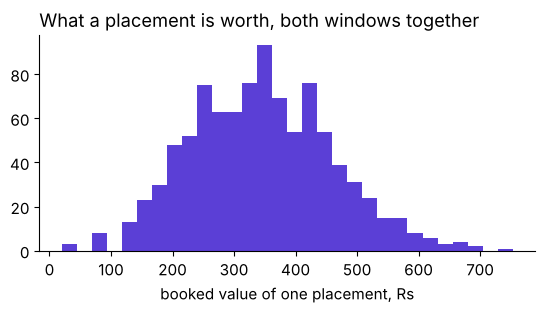

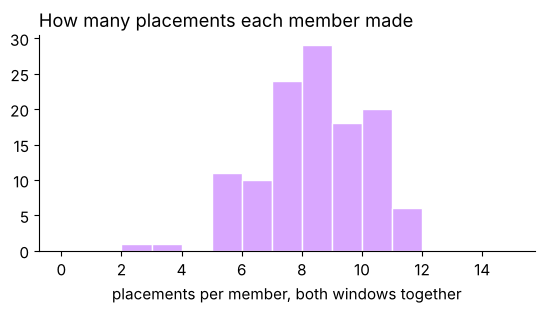

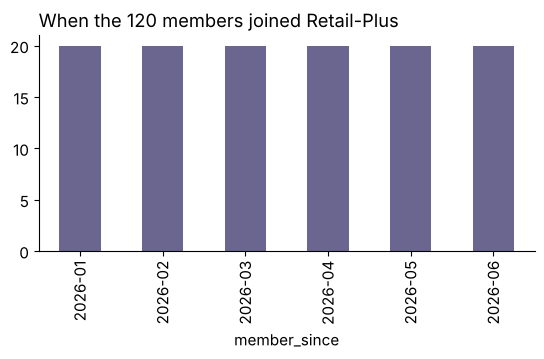

In [2]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.hist(reorders["value_rs"], bins=30, color=VIOLET)
ax.set_xlabel("booked value of one placement, Rs")
ax.set_title("What a placement is worth, both windows together", loc="left")
plt.show()
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.hist(reorders.groupby("customer_id").size(), bins=range(0, 16), color=LAV, edgecolor="white")
ax.set_xlabel("placements per member, both windows together")
ax.set_title("How many placements each member made", loc="left")
plt.show()
fig, ax = plt.subplots(figsize=(6.4, 2.8))
members["member_since"].str[:7].value_counts().sort_index().plot.bar(ax=ax, color=MUTED)
ax.set_title("When the 120 members joined Retail-Plus", loc="left")
plt.show()

## What do seven members' rows say, counted by hand?

Your TA hands out a sheet with seven members' placements and booked values in the two
windows: RP-0002, RP-0012, RP-0014, RP-0021, RP-0023, RP-0031 and RP-0040. Before the ratio
code runs, add up each window's placements and booked value for the seven, divide by seven,
and write the two ratios (window over comparison) on the sheet. The seven cancels out of each
ratio, so the per-member form gives the same answer as the totals; it is the form the head of
Retail-Plus reports. Working without the sheet, type these two lines into the empty cell
below first and run them, where False is the comparison window and True the auto-reorder
window:

```python
seven = ["RP-0002", "RP-0012", "RP-0014", "RP-0021", "RP-0023", "RP-0031", "RP-0040"]
print(reorders[reorders["customer_id"].isin(seven)].groupby(["customer_id", reorders["day"] >= "2026-09-10"])["value_rs"].agg(["size", "sum"]))
```

## What do reorders placed per member and booked value per member do across the two windows?

**Predict before you run.** From the comparison window to the auto-reorder window, reorders
placed per member a) fell; b) held about level; c) rose by up to a third; d) rose by more than
a third. And booked value per member a) fell; b) held about level; c) rose by up to a third;
d) rose by more than a third.

**Your turn.** Then type these lines into the same empty cell and run it again:

```python
comparison = reorders[reorders["day"].between("2026-08-20", "2026-09-09")]
window = reorders[reorders["day"].between("2026-09-10", "2026-09-30")]
placed = (len(window) / 120) / (len(comparison) / 120)
booked = window["value_rs"].sum() / comparison["value_rs"].sum()
print(round(placed, 2), round(booked, 2))
```

`.between(start, end)` keeps the days from the first date to the second, both included.

## Which reorders are these, and what happened to them?

**Your turn.** Type these lines into the empty cell below and run it, then say in one
sentence to your neighbour what the window's placements were and what became of them:

```python
print(window.groupby(["auto", "status"]).size())
print(comparison.groupby(["auto", "status"]).size())
print(window["value_rs"].mean(), comparison["value_rs"].mean())
```

This cell checks the table itself, so a wrong count in your cells cannot come from a broken file.

In [3]:
check("120 Retail-Plus members, one row each", len(members) == 120 and members["customer_id"].is_unique)
check("every placement has a unique id", reorders["reorder_id"].is_unique)
check("every placement falls between 20 August and 30 September", reorders["day"].between("2026-08-20", "2026-09-30").all())
check("every status is delivered, cancelled, merged or pending", reorders["status"].isin(["delivered", "cancelled", "merged", "pending"]).all())
check("every booked value is positive", (reorders["value_rs"] > 0).all())
check("every placement belongs to a member", reorders["customer_id"].isin(members["customer_id"]).all())

PASS 120 Retail-Plus members, one row each
PASS every placement has a unique id
PASS every placement falls between 20 August and 30 September
PASS every status is delivered, cancelled, merged or pending
PASS every booked value is positive
PASS every placement belongs to a member


## What does the lab hand on?

Write on the TA's sheet: your two ratios from the hand count and from the full table, the one
sentence on what the window's placements were and what became of them, and which line of a
complete definition would have stopped "reorders per member" being paid for that.

**The check a senior analyst runs.** The baseline (the comparison window), the denominator
(the 120 members in both windows), the evidence that the thing the number stands for moved
(booked value and what was delivered), and a second way to the same answer (the hand count
against the full table).

The unguided exercise that follows writes the growth plan's own north star, delivered orders
per active customer per month, on the same seven-line template as the morning's.